# Bounding boxes in medical images

`solt.BoundingBoxes` stores the boxes with their labels. The transforms move the corners of the boxes, so the new
box encloses the transformed corners, clipped to the image. At the end, `Stream` drops the boxes, which are mostly
outside of the image or became much smaller relative to it, together with their labels.

The image is a retinal fundus photograph from [scikit-image](https://scikit-image.org). The boxes of the optic disc
and the macula are found below.

In [1]:
%matplotlib inline
# JPEG keeps the notebook small, since the figures are photos
%config InlineBackend.figure_formats = ['jpeg']
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

import solt
import solt.transforms as slt

# SOLT samples the transforms with the `random` module
random.seed(42)
np.random.seed(42)

from scipy import ndimage as ndi
from skimage import color, data, filters, measure, morphology

## Getting the data

In [2]:
img = cv2.resize(data.retina(), (1024, 1024), interpolation=cv2.INTER_AREA)
field_of_view = morphology.erosion(color.rgb2gray(img) > 0.08, morphology.disk(5))

# The optic disc is the brightest region of the blue channel
blue = filters.gaussian(img[..., 2] / 255.0, sigma=11)
disc = measure.label((blue > np.percentile(blue[field_of_view], 99)) & field_of_view)
y0, x0, y1, x1 = max(measure.regionprops(disc), key=lambda r: r.area).bbox
disc_box = (x0, y0, x1 - x0, y1 - y0)

# The macula is the darkest region of the green channel. The border of the field of view is excluded,
# since it has dark camera artefacts. Let's make the box of the macula of the same size as of the disc
green = filters.gaussian(img[..., 1] / 255.0, sigma=18)
green[ndi.distance_transform_edt(field_of_view) < 100] = 1
cy, cx = np.unravel_index(np.argmin(green), green.shape)
size = max(x1 - x0, y1 - y0)
macula_box = (int(cx) - size // 2, int(cy) - size // 2, size, size)

# The boxes are (x, y, width, height), i.e. in the COCO format. The VOC, YOLO and cxcywh formats work as well
h, w = img.shape[:2]
bboxes = solt.BoundingBoxes([disc_box, macula_box], h, w, fmt='coco', labels=['Optic disc', 'Macula'])
bboxes.data

array([[114., 415., 220., 539.],
       [451., 449., 575., 573.]])

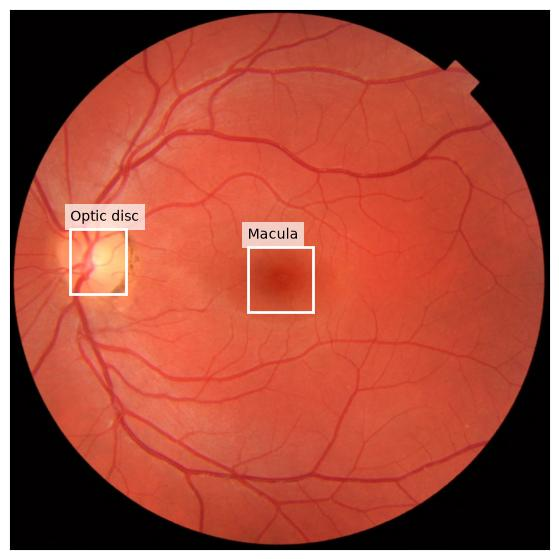

In [3]:
def show_boxes(ax, img, bboxes):
    ax.imshow(img)
    for (x, y, w, h), name in zip(bboxes.to('coco'), bboxes.labels):
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color='w', lw=2))
        ax.text(x, y - 15, name, fontsize=10, bbox=dict(facecolor='white', alpha=0.7, lw=0))
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(1, 1, figsize=(7, 7))
show_boxes(ax, img, bboxes)
plt.show()

## Defining a pipeline

In [4]:
stream = solt.Stream([
    slt.Projection(
        solt.Stream([
            slt.Scale(range_x=(0.8, 1.1), p=1),
            slt.Rotate(angle_range=(-90, 90), p=1),
            slt.Shear(range_x=(-0.2, 0.2), range_y=None, p=0.7),
        ]),
        v_range=(1e-6, 3e-4), p=1),
    # Various cropping and padding tricks
    slt.Pad(1000, 'z'),
    slt.Crop(1000, crop_mode='c'),
    slt.Crop(950, crop_mode='r'),
    slt.Pad(1000, 'z'),
    # Intensity augmentations
    slt.GammaCorrection(p=1, gamma_range=(0.5, 3)),
    solt.SelectiveStream([
        solt.SelectiveStream([
            slt.SaltAndPepper(p=1, gain_range=0.01),
            slt.Blur(p=0.5, blur_type='m', k_size=(11,)),
        ]),
        slt.Noise(p=1, gain_range=0.5),
    ]),
])
print(stream.to_yaml())

stream:
  ignore_fast_mode: false
  in_place: true
  interpolation: null
  max_bbox_area_loss: 0.9
  max_bbox_outside: 0.5
  optimize_stack: false
  padding: null
  shuffle: false
  transforms:
  - projection:
      affine_transforms:
        stream:
          ignore_fast_mode: false
          in_place: true
          interpolation: null
          max_bbox_area_loss: 0.9
          max_bbox_outside: 0.5
          optimize_stack: false
          padding: null
          shuffle: false
          transforms:
          - scale:
              ignore_fast_mode: false
              ignore_state: true
              interpolation:
              - bilinear
              - inherit
              p: 1
              padding:
              - z
              - inherit
              range_x:
              - 0.8
              - 1.1
              range_y: null
              same: true
          - rotate:
              angle_range:
              - -90
              - 90
              ignore_fast_mode: false

## Augmentation results

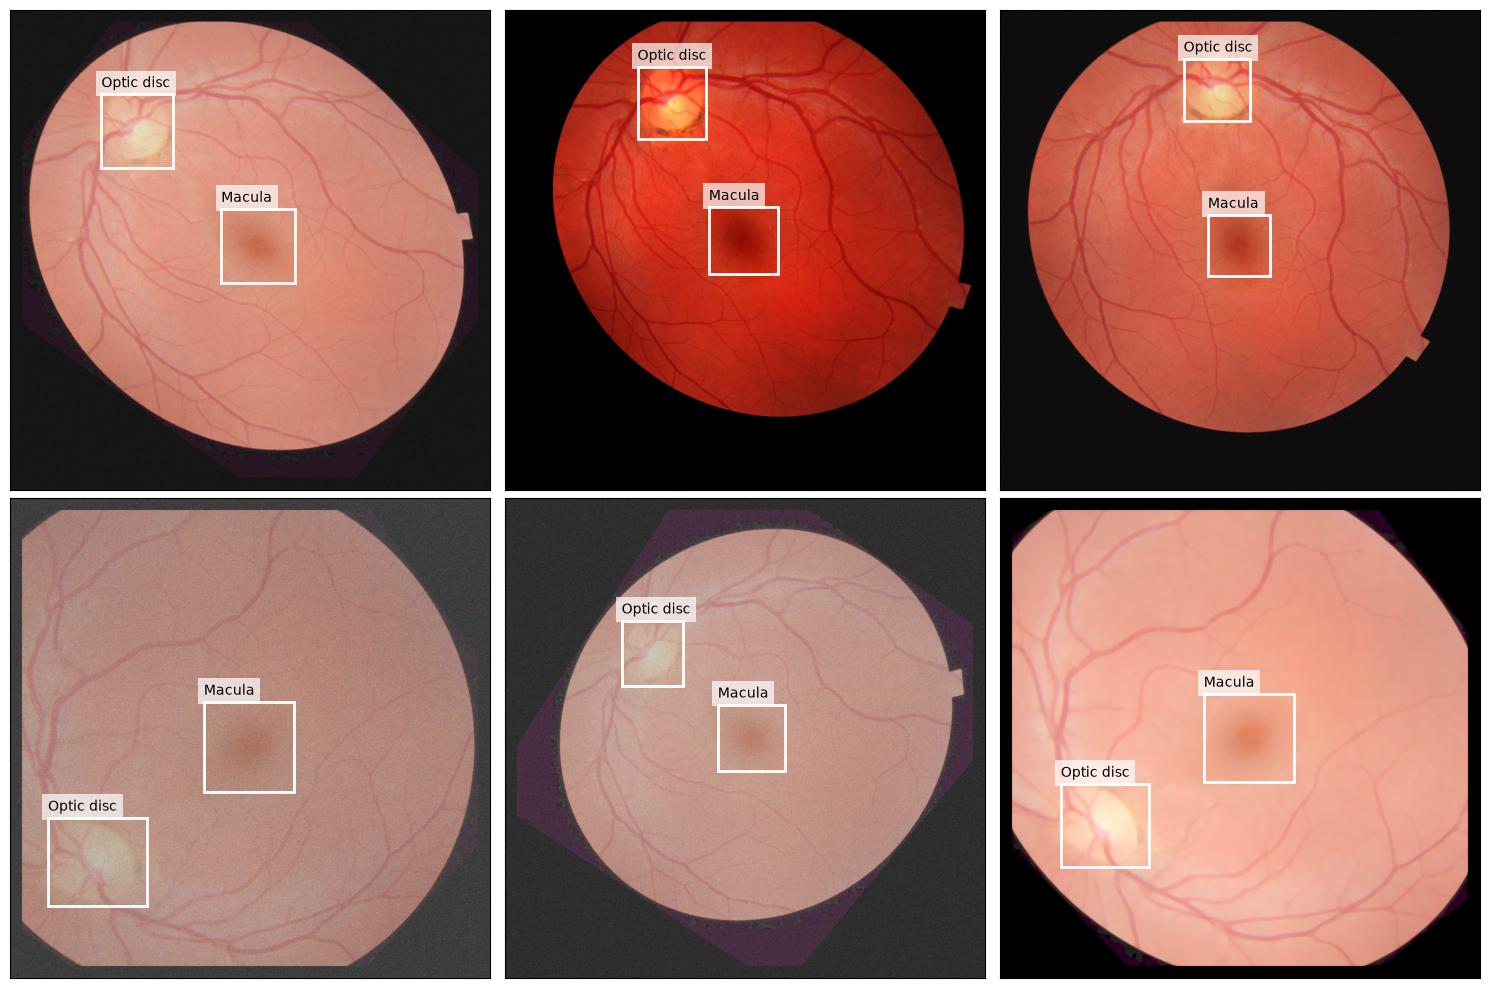

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax in axes.ravel():
    img_res, bboxes_res = stream({'image': img, 'bboxes': bboxes}, return_torch=False).data
    show_boxes(ax, img_res, bboxes_res)
plt.tight_layout()
plt.show()

## Clipping and dropping

A crop, which cuts a part of a box, clips it. If more than `max_bbox_outside` (50% by default) of a box is outside of
the image, it is dropped with its label. `max_bbox_area_loss` (90% by default) drops the boxes, which became more
than 10 times smaller relative to the image.

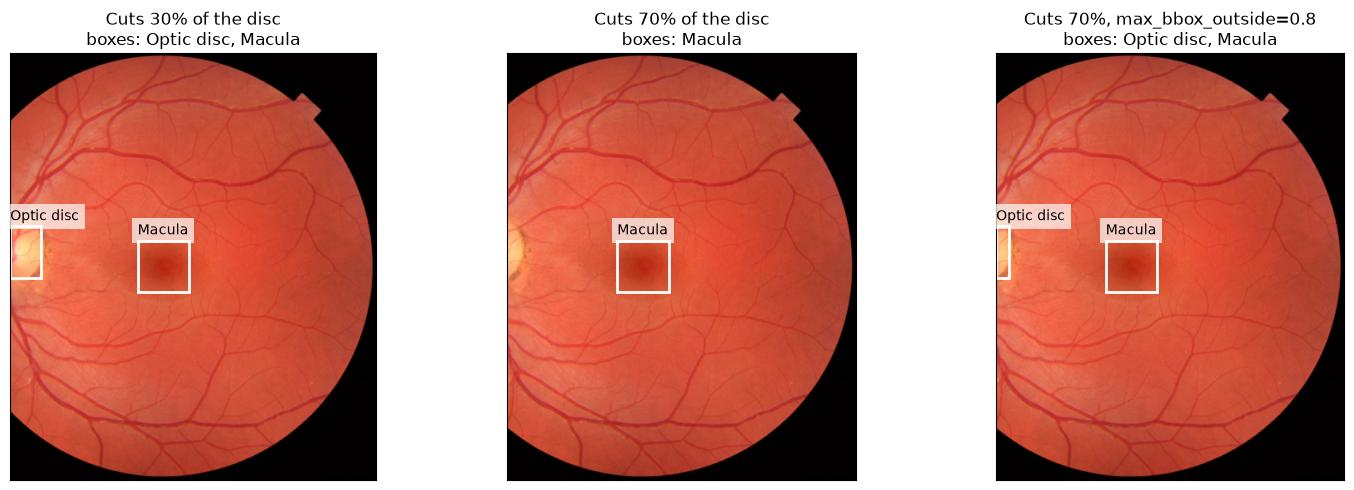

In [6]:
def crop_cutting(fraction):
    """A crop, which cuts a fraction of the optic disc box from the left."""
    x0, _, x1, _ = bboxes.data[0]
    left = int(x0 + fraction * (x1 - x0))
    return slt.Crop(crop_to=(w - left, h), crop_mode='rt')


examples = [
    ('Cuts 30% of the disc', crop_cutting(0.3), {}),
    ('Cuts 70% of the disc', crop_cutting(0.7), {}),
    ('Cuts 70%, max_bbox_outside=0.8', crop_cutting(0.7), {'max_bbox_outside': 0.8}),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, crop, kwargs) in zip(axes, examples):
    img_res, bboxes_res = solt.Stream([crop], **kwargs)({'image': img, 'bboxes': bboxes}, return_torch=False).data
    show_boxes(ax, img_res, bboxes_res)
    ax.set_title(f'{title}\nboxes: {", ".join(bboxes_res.labels)}')
plt.tight_layout()
plt.show()

## PyTorch

The boxes become the target format of the detection models of torchvision.

In [7]:
stream({'image': img, 'bboxes': bboxes}, normalize=False)['bboxes']

{'boxes': tensor([[211.6674, 617.1166, 366.4196, 768.5551],
         [445.9140, 406.5273, 589.5957, 550.1787]]),
 'labels': ['Optic disc', 'Macula']}